In [1]:
import os
import psycopg2
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv
root = Path.cwd()
while not (root / "pyproject.toml").is_file():
    if root == root.parent:
        raise RuntimeError("Start the notebook from inside the cloned project.")
    root = root.parent

load_dotenv(root / "prod.env")

neon_connection_string = os.environ.get("NEON_DATABASE_URL")
openai_api_key = os.environ.get("OPENAI_KEY")




In [9]:

def plot_paper_graph(target_paper_id: str):
    """Fetches a 1-hop subgraph for a specific paper and plots it."""
    
    # 1. SQL Query to get all edges and node details connected to the paper
    query = """
        SELECT 
            e.source, sn.name AS source_name, sn.label AS source_label,
            e.target, tn.name AS target_name, tn.label AS target_label,
            e.relation
        FROM kg_edges e
        JOIN kg_nodes sn ON e.source = sn.id
        JOIN kg_nodes tn ON e.target = tn.id
        WHERE e.source = %s OR e.target = %s;
    """


    # query = """
    #     WITH hop1 AS (
    #         -- 1st Hop: Edges directly connected to the target paper
    #         SELECT source, target, relation
    #         FROM kg_edges
    #         WHERE source = %s OR target = %s
    #     ),
    #     hop1_nodes AS (
    #         -- Collect all unique nodes found in the 1st hop
    #         SELECT source AS node_id FROM hop1
    #         UNION
    #         SELECT target AS node_id FROM hop1
    #     ),
    #     hop2 AS (
    #         -- 2nd Hop: Edges connected to the nodes from the 1st hop
    #         SELECT e.source, e.target, e.relation
    #         FROM kg_edges e
    #         JOIN hop1_nodes n ON e.source = n.node_id OR e.target = n.node_id
    #         -- Limit to prevent the plot from becoming too big
    #         LIMIT 30
    #     ),
    #     combined_edges AS (
    #         SELECT source, target, relation FROM hop1
    #         UNION
    #         SELECT source, target, relation FROM hop2
    #     )
    #     SELECT 
    #         c.source, sn.name AS source_name, sn.label AS source_label,
    #         c.target, tn.name AS target_name, tn.label AS target_label,
    #         c.relation
    #     FROM combined_edges c
    #     JOIN kg_nodes sn ON c.source = sn.id
    #     JOIN kg_nodes tn ON c.target = tn.id;
    
    # """
    
    conn = psycopg2.connect(neon_connection_string)
    try:
        with conn.cursor() as cur:
            cur.execute(query, (target_paper_id, target_paper_id))
            results = cur.fetchall()
    finally:
        conn.close()

    if not results:
        print(f"No graph data found for {target_paper_id}")
        return

    # 2. Build the NetworkX Graph
    G = nx.DiGraph()
    
    for row in results:
        src_id, src_name, src_label, tgt_id, tgt_name, tgt_label, relation = row
        
        # Add nodes with their display names and categories
        G.add_node(src_id, name=src_name, label=src_label)
        G.add_node(tgt_id, name=tgt_name, label=tgt_label)
        
        # Add the connecting edge
        G.add_edge(src_id, tgt_id, label=relation)

    # 3. Assign Colors based on Node Label (Ontology)
    color_map = {
        "Publication": "#FF9999",       # Light Red
        "Author": "#99CCFF",           # Light Blue
        "Method": "#99FF99",           # Light Green
        "Task": "#FFCC99",             # Orange
        "Medical_Condition": "#FF99FF",# Pink
        "Data_Modality": "#FFFF99",    # Yellow
        "Metric": "#E0E0E0"            # Light Gray
    }
    
    node_colors = [
        color_map.get(G.nodes[n].get("label"), "#CCCCCC") 
        for n in G.nodes()
    ]
    
    # Extract clean display names for the plot labels
    node_labels = {n: G.nodes[n]["name"] for n in G.nodes()}
    edge_labels = {(u, v): d["label"] for u, v, d in G.edges(data=True)}

    # 4. Draw the Graph
    plt.figure(figsize=(12, 8))
    
    # Use a spring layout to automatically space out the nodes around the central paper
    pos = nx.spring_layout(G, k=0.5, seed=42)
    
    # Draw nodes and node labels
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000, edgecolors="black")
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=9, font_weight="bold")
    
    # Draw edges and relationship text
    nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=15, edge_color="gray")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, font_color="red")
    
    plt.title(f"Knowledge Graph for: {target_paper_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [3]:
sample_paper_id = "paper:arxiv:2112.15011" 
plot_paper_graph(sample_paper_id)

No graph data found for paper:arxiv:2112.15011


In [4]:
import psycopg2
from langchain_openai import OpenAIEmbeddings

def search_documents_via_graph(user_query: str):
    """
    Finds documents by semantically matching the query to graph nodes, 
    then traversing edges to find connected publications.
    """
    # 1. Embed the query (already normalized by OpenAI)
    embedder = OpenAIEmbeddings(model="text-embedding-3-small", openai_api_key=openai_api_key, dimensions=512)
    query_vector = embedder.embed_query(user_query)

    # 2. SQL to hit the FlatNav index first, then traverse the edges
    sql_query = """
        WITH matched_concepts AS (
            SELECT id, name, label
            FROM kg_nodes
            WHERE label IN ('Method', 'Task', 'Medical_Condition', 'Data_Modality', 'Metric')
            ORDER BY embedding <#> %s::vector
            LIMIT 3
        ),
        connected_documents AS (
            SELECT 
                c.name AS matched_concept,
                c.label AS concept_type,
                n.id AS paper_id,
                n.name AS paper_title
            FROM matched_concepts c
            JOIN kg_edges e ON c.id = e.target OR c.id = e.source
            JOIN kg_nodes n ON (e.source = n.id OR e.target = n.id)
            WHERE n.label = 'Publication' AND n.id != c.id
        )
        SELECT DISTINCT paper_id, paper_title, matched_concept, concept_type
        FROM connected_documents
        LIMIT 5;
    """

    conn = psycopg2.connect(neon_connection_string)
    try:
        with conn.cursor() as cur:
            #https://neon.com/blog/understanding-vector-search-and-hnsw-index-with-pgvector
            cur.execute("SET hnsw.ef_search = 100;")
            cur.execute(sql_query, (query_vector,))
            results = cur.fetchall()
    finally:
        conn.close()

    if not results:
        print("No related documents found.")
        return

    print(f"--- Search Results for: '{user_query}' ---\n")
    for paper_id, paper_title, matched_concept, concept_type in results:
        print(f"Paper: {paper_title}")
        print(f"ID: {paper_id}")
        print(f"Matched via {concept_type}: {matched_concept}\n")

In [5]:
search_documents_via_graph("Chest X-ray")

--- Search Results for: 'Chest X-ray' ---

Paper: AI-driven pneumonia diagnosis from chest x-rays
ID: paper:openalex:W4413437104
Matched via Data_Modality: chest x-ray images

Paper: Lung Mass Identification Using Tiny Deep Learning Based on Lightweight MobileNet and Raspberry Pi 5 for Low Source Medical Diagnostic
ID: paper:openalex:W4414188134
Matched via Data_Modality: chest x-ray images

Paper: Chest X-Ray Image Analysis and Report Generation Using Advanced Deep Learning Techniques and NLP
ID: paper:openalex:W4414231516
Matched via Data_Modality: chest x-ray images

Paper: Real-Time Multi-Class Pneumonia Detection in Chest X-Rays Using Optimized Deep Learning Methods
ID: paper:openalex:W4414603995
Matched via Data_Modality: chest x-ray images

Paper: Enhancing Chest X-Ray Image Analysis for Pneumonia, Normal, and COVID Classification Using Deep Learning
ID: paper:openalex:W4414604349
Matched via Data_Modality: chest x-ray images



In [11]:
query_two_concepts = """
SELECT
    p.id AS paper_id,
    p.name AS title,
    p.properties->>'source' AS source,
    p.properties->>'source_id' AS source_id,
    p.properties->>'doi' AS doi
FROM kg_nodes p
WHERE p.label = 'Publication'
  AND EXISTS (
      SELECT 1
      FROM kg_edges e
      JOIN kg_nodes node ON node.id = e.target
      WHERE e.source = p.id
        AND node.label NOT IN ('Publication', 'Author', 'Reference')
        AND node.name ILIKE '%radiolog%'
  )
  AND EXISTS (
      SELECT 1
      FROM kg_edges e
      JOIN kg_nodes node ON node.id = e.target
      WHERE e.source = p.id
        AND node.label NOT IN ('Publication', 'Author', 'Reference')
        AND node.name ILIKE '%machine learning%'
  )
ORDER BY p.name, p.id
LIMIT 50;"""

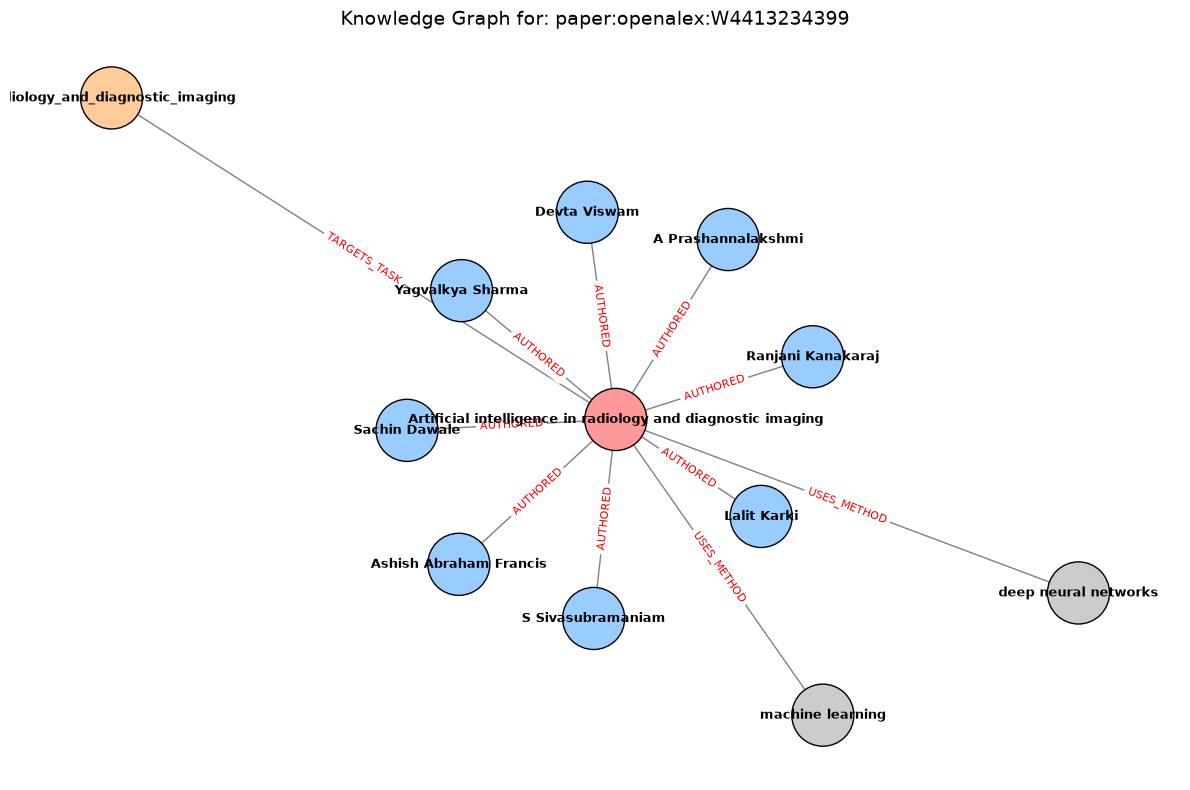

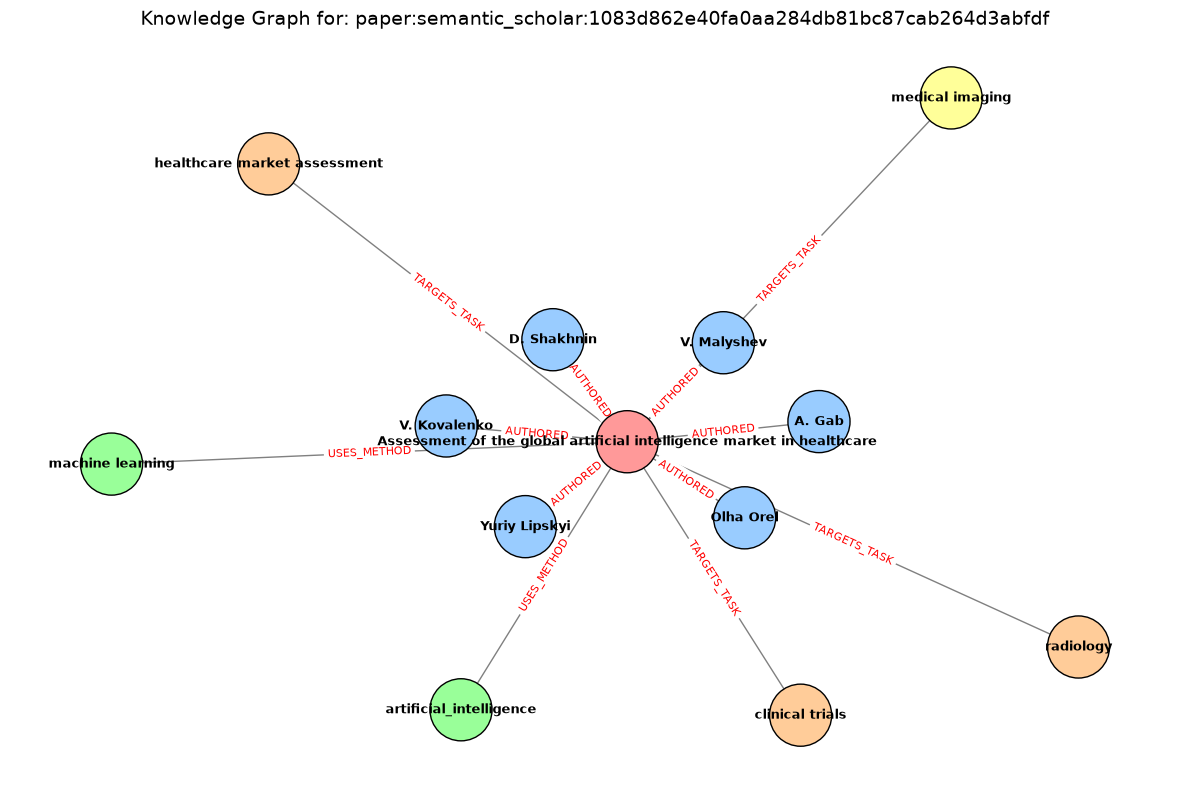

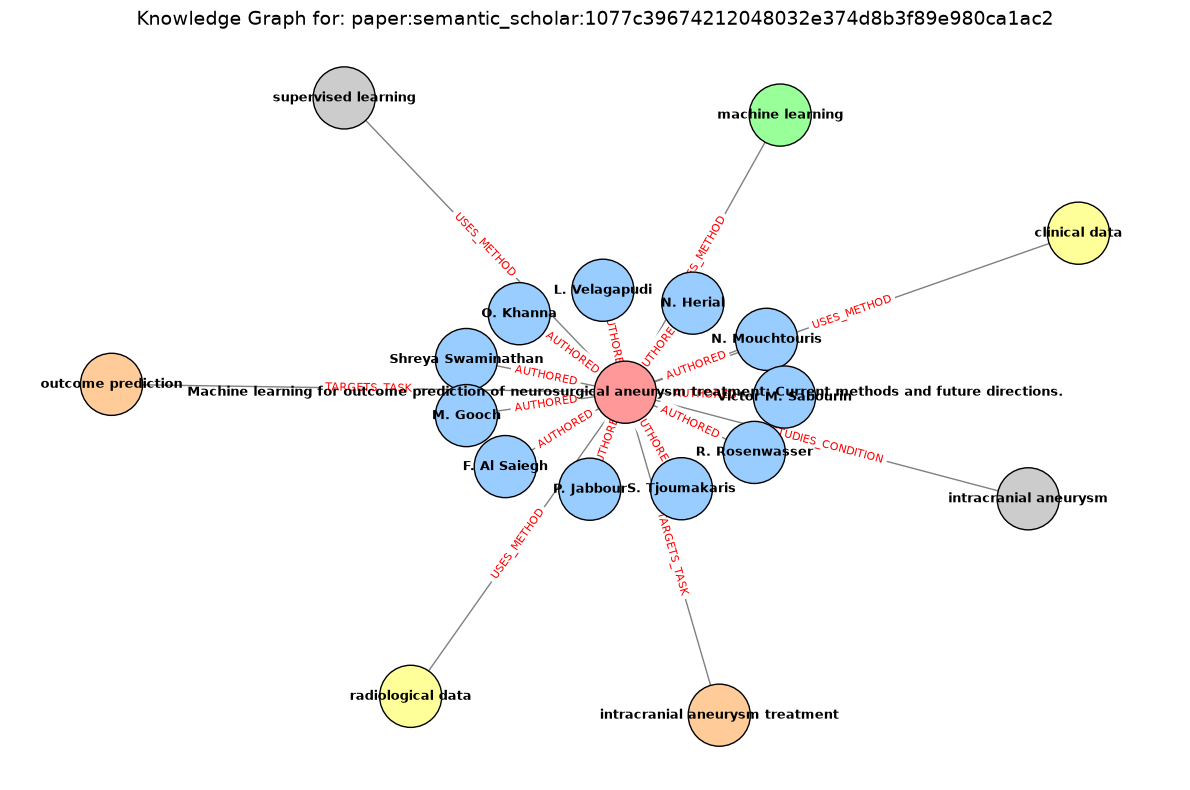

In [12]:
conn = psycopg2.connect(neon_connection_string)
try:
    with conn.cursor() as cur:
        cur.execute(query_two_concepts)
        results = cur.fetchall()
finally:
    conn.close()

for row in results:
    plot_paper_graph(row[0])